<center><h1>Satish_Manvika_HW5</h1></center>
<br>
<br>

Name: Manvika Satish
<br>
Github Username: manvsatish
<br>
USC ID: 5582061880

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
from pathlib import Path # data handling
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt # plotting
import seaborn as sns

from sklearn.impute import SimpleImputer # preprocessing& model selection
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text # classification tree
from sklearn.metrics import accuracy_score

# regression mods
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
# boosting
from xgboost import XGBRegressor

# notebook settings
RANDOM_STATE = 552
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 150)

print("Packages imported successfully.")

Packages imported successfully.


### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
diagnosis_path = Path("../data/diagnosis.data")

#6 preds, 2 labels
diagnosis_columns = ["temperature", "nausea", "lumbar_pain", "urine_pushing", "micturition_pains", "burning_urethra", "bladder_inflammation", "nephritis"]
diagnosis_raw = pd.read_csv(diagnosis_path, sep="\t", header=None, names=diagnosis_columns, encoding="utf-16", decimal=",") #tab sep utf file
print("Raw dataset shape:", diagnosis_raw.shape)
display(diagnosis_raw.head())

binary_columns = diagnosis_columns[1:] # yes/no column -> 1/0

diagnosis_data = diagnosis_raw.copy()
diagnosis_data[binary_columns] = diagnosis_data[binary_columns].replace({"no": 0, "yes": 1}).astype(int)

#verify ds before modeling
assert diagnosis_data.shape == (120, 8)
assert diagnosis_data.isna().sum().sum() == 0
assert diagnosis_data[binary_columns].isin([0, 1]).all().all()
print("Encoded dataset shape:", diagnosis_data.shape)
print("Total missing values:", diagnosis_data.isna().sum().sum())
print("\nEncoded data types:")
display(diagnosis_data.dtypes.to_frame(name="Data Type"))

print("\nFirst five encoded rows:")
display(diagnosis_data.head())

print("\nLabel combination counts:")
display(diagnosis_data[["bladder_inflammation", "nephritis"]].value_counts().sort_index().to_frame(name="Count"))

Raw dataset shape: (120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


Encoded dataset shape: (120, 8)
Total missing values: 0

Encoded data types:


,Data Type
temperature,float64
nausea,int64
lumbar_pain,int64
urine_pushing,int64
micturition_pains,int64
burning_urethra,int64
bladder_inflammation,int64
nephritis,int64



First five encoded rows:


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0



Label combination counts:


Count
bladder_inflammation nephritis       
0                    0             30
                     1             31
1                    0             40
                     1             19

### (b) Build a decision tree

Label-powerset class counts:


,Count
Bladder inflammation only,40
Nephritis only,31
Neither,30
Both diagnoses,19


Tree depth: 4
Number of leaves: 6
Number of nodes: 11
Whole-dataset accuracy: 1.0


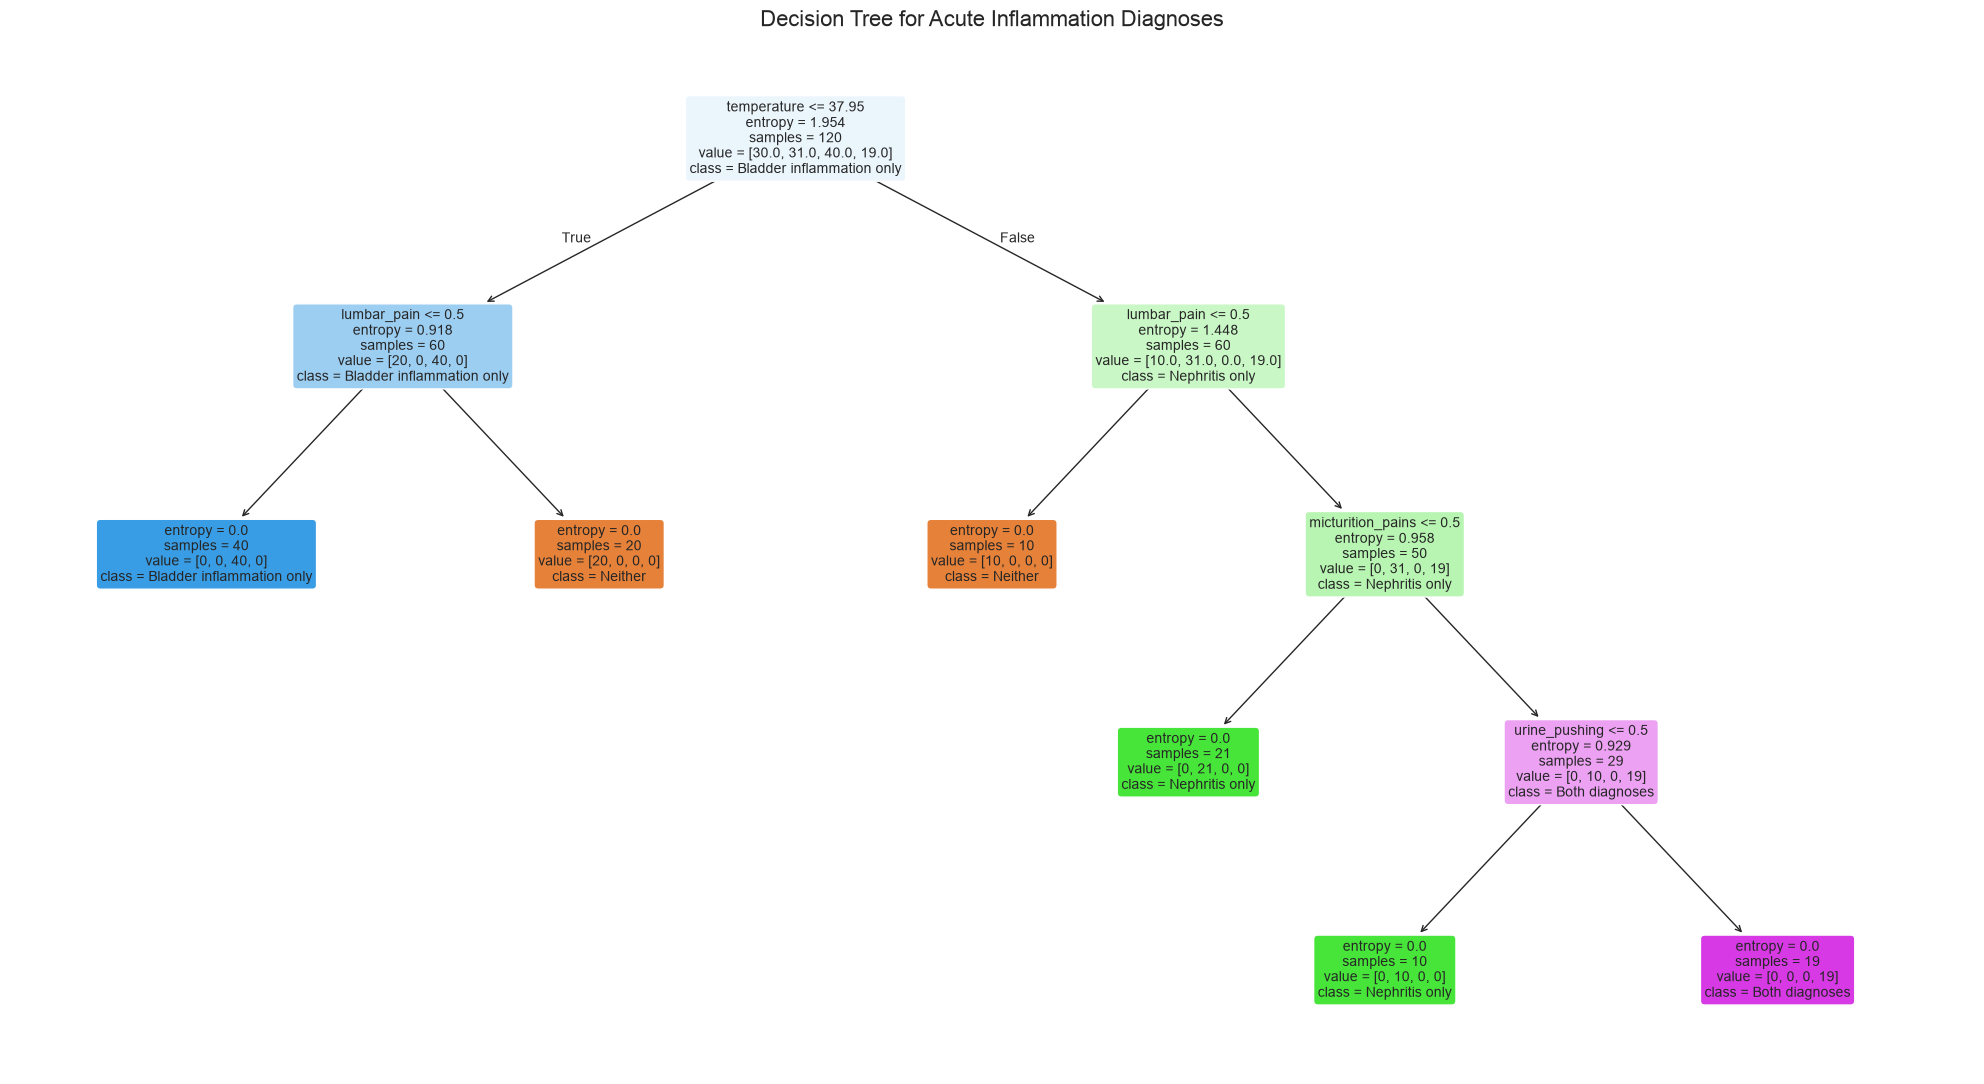

In [3]:
# sep 6 predictors from 2 diag labels
diagnosis_feature_names = ["temperature", "nausea", "lumbar_pain", "urine_pushing", "micturition_pains", "burning_urethra"]
X_diagnosis = diagnosis_data[diagnosis_feature_names].copy()
y_diagnosis = diagnosis_data[["bladder_inflammation", "nephritis"]].copy()
y_powerset = y_diagnosis.astype(str).agg("_".join, axis=1) # combine 2 bin labels into one label-powerset class

class_name_map = {"0_0": "Neither", "0_1": "Nephritis only", "1_0": "Bladder inflammation only", "1_1": "Both diagnoses"}
print("Label-powerset class counts:")
display(y_powerset.map(class_name_map).value_counts().to_frame(name="Count"))

# build decision tree on the entire ds
full_tree = DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE)
full_tree.fit(X_diagnosis, y_powerset)

# calc ds predictions and accuracy
full_tree_predictions = full_tree.predict(X_diagnosis)
full_tree_accuracy = accuracy_score(y_powerset, full_tree_predictions)
print("Tree depth:", full_tree.get_depth())
print("Number of leaves:", full_tree.get_n_leaves())
print("Number of nodes:", full_tree.tree_.node_count)
print("Whole-dataset accuracy:", round(full_tree_accuracy, 4))

# create readable class names in the tree's class order
tree_class_names = [class_name_map[class_label] for class_label in full_tree.classes_]
plt.figure(figsize=(20, 11)) # plot complete decision tree

plot_tree(full_tree, feature_names=diagnosis_feature_names, class_names=tree_class_names, filled=True, rounded=True, impurity=True, proportion=False, fontsize=10)
plt.title("Decision Tree for Acute Inflammation Diagnoses", fontsize=16)
plt.tight_layout()
plt.show()

### (c) Convert the decision rules

In [4]:
#follow each path from the root to leaf recursively
def recurse_if_then_rules(model, feature_names, class_map, node, conditions, rule_number):
    tree_structure = model.tree_
    feature_index = tree_structure.feature[node]
 
    if feature_index != -2:  # continue splitting if the current node is not a leaf
        feature_name = feature_names[feature_index]
        threshold = tree_structure.threshold[node]
        
        if feature_name != "temperature" and np.isclose(threshold, 0.5): # make binary conditions easier to interpret
            left_condition = f"{feature_name} = no"
            right_condition = f"{feature_name} = yes"
        else:
            left_condition = f"{feature_name} <= {threshold:.2f}"
            right_condition = f"{feature_name} > {threshold:.2f}"

        # recursive funcs
        rule_number = recurse_if_then_rules(model, feature_names, class_map, tree_structure.children_left[node], conditions + [left_condition], rule_number)
        rule_number = recurse_if_then_rules(model, feature_names, class_map, tree_structure.children_right[node], conditions + [right_condition], rule_number)

    # print the diagnosis when a leaf is reached
    else:
        class_index = np.argmax(tree_structure.value[node][0])
        class_code = model.classes_[class_index]
        diagnosis = class_map[class_code]
        sample_count = tree_structure.n_node_samples[node]
        print(
            f"Rule {rule_number}: IF "
            + " AND ".join(conditions)
            + f" THEN diagnosis = {diagnosis} "
            + f"(samples = {sample_count})"
        )
        rule_number += 1

    return rule_number


# start the recursive rule extraction at the root node
def print_if_then_rules(model, feature_names, class_map):
    recurse_if_then_rules(model=model, feature_names=feature_names, class_map=class_map, node=0, conditions=[], rule_number=1)

print("IF-THEN decision rules:\n")
print_if_then_rules(full_tree, diagnosis_feature_names, class_name_map)

IF-THEN decision rules:

Rule 1: IF temperature <= 37.95 AND lumbar_pain = no THEN diagnosis = Bladder inflammation only (samples = 40)
Rule 2: IF temperature <= 37.95 AND lumbar_pain = yes THEN diagnosis = Neither (samples = 20)
Rule 3: IF temperature > 37.95 AND lumbar_pain = no THEN diagnosis = Neither (samples = 10)
Rule 4: IF temperature > 37.95 AND lumbar_pain = yes AND micturition_pains = no THEN diagnosis = Nephritis only (samples = 21)
Rule 5: IF temperature > 37.95 AND lumbar_pain = yes AND micturition_pains = yes AND urine_pushing = no THEN diagnosis = Nephritis only (samples = 10)
Rule 6: IF temperature > 37.95 AND lumbar_pain = yes AND micturition_pains = yes AND urine_pushing = yes THEN diagnosis = Both diagnoses (samples = 19)


## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

### (b) Missing values

### (c) Plot a correlation matrix

### (d) Calculate the Coefficient of Variation CV

### (e) Scatter plots and box plots for highest CV features

### (f) Fit a linear model

### (g) Fit a ridge regression model

### (h) Fit a LASSO model

### (i) Fit a PCR model

### (j) Fit a boosting tree